### bài 28: 
Dùng Python thực hiện các yêu cầu sau:
a. Tạo mảng các thẻ ở Bài 9; dùng numpy tính trung bình và phương sai.
b. Mô phỏng 5000 trung bình mẫu khi rút có hoàn lại với 𝑛 = 25 và 𝑛 = 100. So sánh trung bình và
độ lệch chuẩn thực nghiệm với lý thuyết ở Bài 10.
c. Vẽ hai biểu đồ mật độ thực nghiệm trên cùng một hình và giải thích vì sao biểu đồ ứng với 𝑛 = 100
hẹp hơn.
d. Mô phỏng 5000 trung bình của 30 biến mũ có trung bình 5. Chuẩn hóa kết quả và chồng đường
cong chuẩn tắc để minh họa định lý giới hạn trung tâm.


a. Trung bình: 1.9
   Phương sai: 2.09

b. n = 25
Trung bình thực nghiệm: 1.9050
Trung bình lý thuyết:    1.9000
Sai lệch trung bình:     0.0050
Độ lệch chuẩn thực nghiệm: 0.2883
Độ lệch chuẩn lý thuyết:   0.2891
Sai lệch độ lệch chuẩn:    0.0008

b. n = 100
Trung bình thực nghiệm: 1.8962
Trung bình lý thuyết:    1.9000
Sai lệch trung bình:     0.0038
Độ lệch chuẩn thực nghiệm: 0.1460
Độ lệch chuẩn lý thuyết:   0.1446
Sai lệch độ lệch chuẩn:    0.0014
c, Biểu đồ mật độ thực nghiệm trên cùng một hình



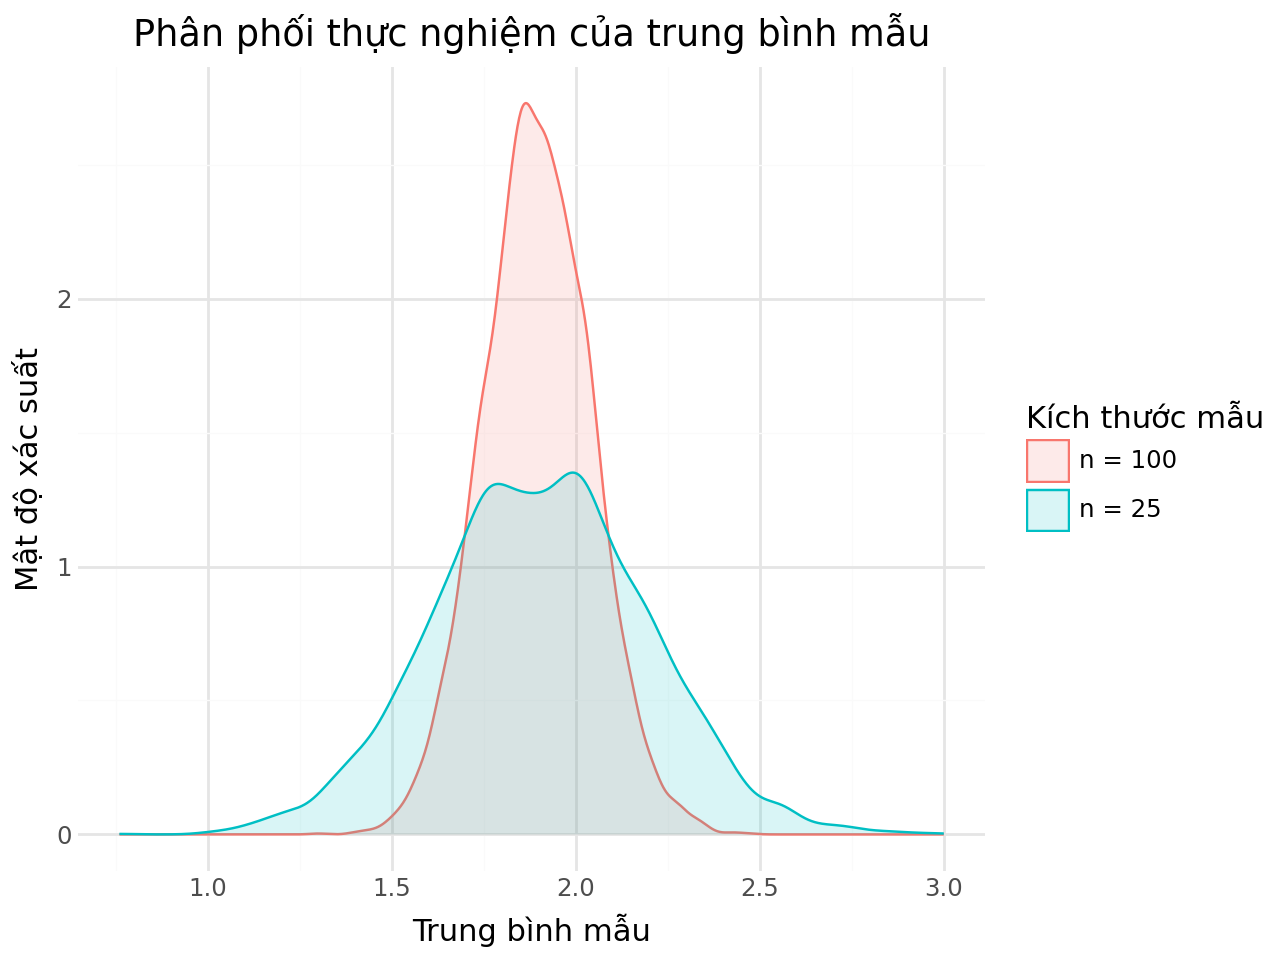

Biểu đồ mật độ thực nghiệm ứng với (n=100) hẹp hơn biểu đồ ứng với (n=25)
Vì độ lệch chuẩn của trung bình mẫu giảm khi kích thước mẫu tăng.
Cụ thể, E(Xn)=1,9 và SD(Xn)=\sigma/\sqrt{n}).
Khi kích thước mẫu tăng từ 25 lên 100, độ lệch chuẩn của trung bình mẫu giảm từ khoảng 0,2891 xuống 0,1446.
Do đó, các giá trị trung bình mẫu với (n=100) tập trung gần giá trị kỳ vọng hơn, làm phân phối ít phân tán và đường cong mật độ hẹp hơn.
Cả hai phân phối đều tập trung quanh 1,9.

d. Mô phỏng 5000 trung bình của 30 biến mũ có trung bình 5.
Chuẩn hóa kết quả và chồng đường cong chuẩn tắc để minh họa định lý giới hạn trung tâm


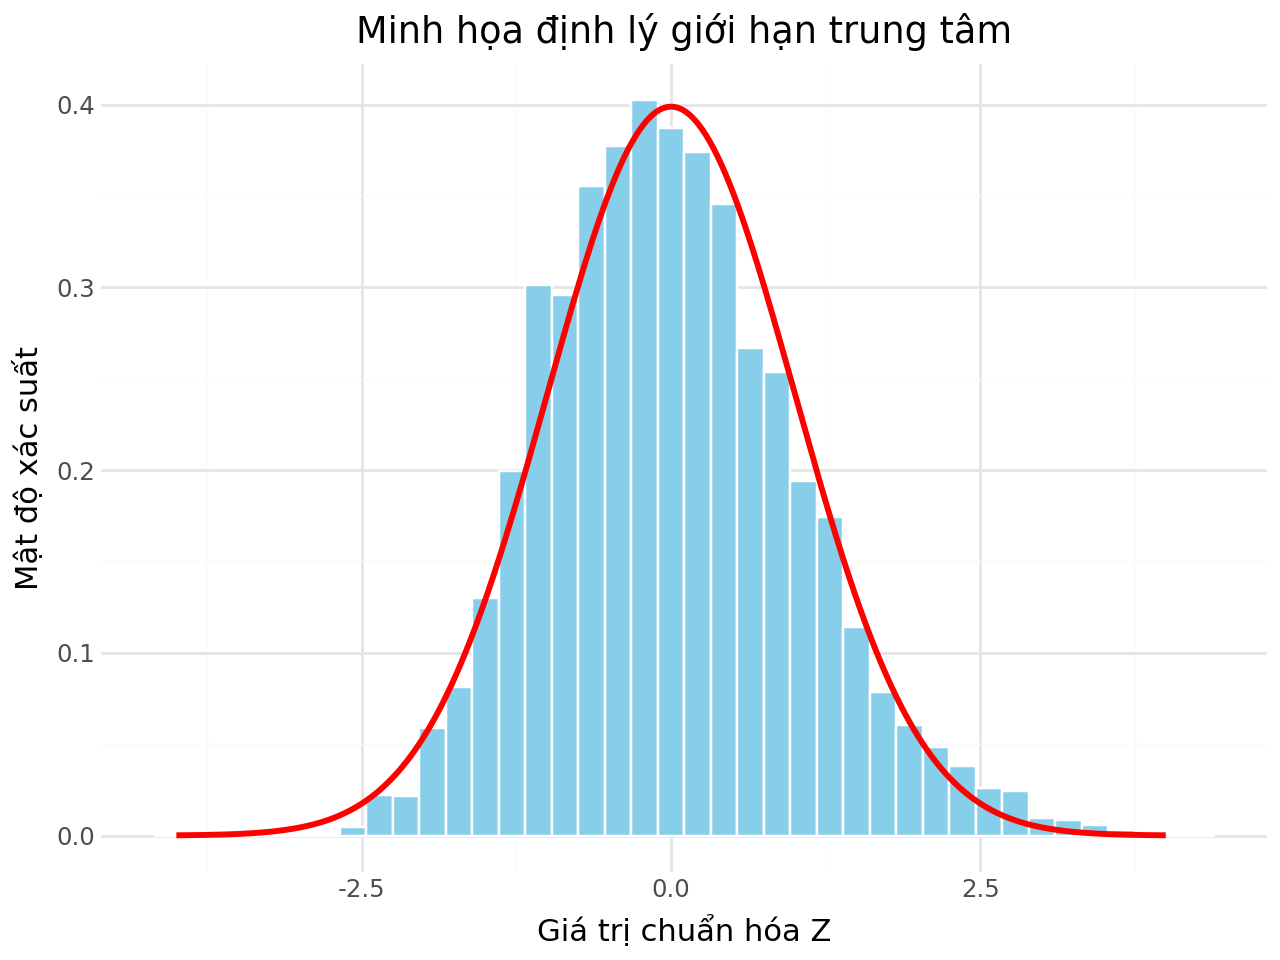

In [2]:
import numpy as np
import pandas as pd
from scipy.stats import norm
from plotnine import *

cards = np.array([0, 0, 1, 1, 1, 2, 3, 3, 4, 4])

mu = np.mean(cards)
var = np.var(cards)
sigma = np.sqrt(var)

print("a. Trung bình:", mu)
print("   Phương sai:", round(var, 2))

np.random.seed(42)

N = 5000
sample_means = {}

for n in [25, 100]:
    samples = np.random.choice(
        cards, size=(N, n), replace=True
    )
    means = np.mean(samples, axis=1)
    sample_means[n] = means

    mean_exp = np.mean(means)
    sd_exp = np.std(means)

    mean_theory = mu
    sd_theory = sigma / np.sqrt(n)

    print(f"\nb. n = {n}")
    print(f"Trung bình thực nghiệm: {mean_exp:.4f}")
    print(f"Trung bình lý thuyết:    {mean_theory:.4f}")
    print(f"Sai lệch trung bình:     {abs(mean_exp - mean_theory):.4f}")

    print(f"Độ lệch chuẩn thực nghiệm: {sd_exp:.4f}")
    print(f"Độ lệch chuẩn lý thuyết:   {sd_theory:.4f}")
    print(f"Sai lệch độ lệch chuẩn:    {abs(sd_exp - sd_theory):.4f}")

df_means = pd.concat([
    pd.DataFrame({
        "Trung bình mẫu": sample_means[n],
        "Kích thước mẫu": f"n = {n}"
    })
    for n in [25, 100]
], ignore_index=True)

plot_c = (
    ggplot(df_means, aes(
        x="Trung bình mẫu",
        color="Kích thước mẫu",
        fill="Kích thước mẫu"
    ))
    + geom_density(alpha=0.15)
    + labs(
        title="Phân phối thực nghiệm của trung bình mẫu",
        x="Trung bình mẫu",
        y="Mật độ xác suất",
        color="Kích thước mẫu",
        fill="Kích thước mẫu"
    )
    + theme_minimal()
)
print('c, Biểu đồ mật độ thực nghiệm trên cùng một hình')
print()
plot_c.show()
print('Biểu đồ mật độ thực nghiệm ứng với (n=100) hẹp hơn biểu đồ ứng với (n=25)')
print('Vì độ lệch chuẩn của trung bình mẫu giảm khi kích thước mẫu tăng.')
print('Cụ thể, E(Xn)=1,9 và SD(Xn)=\sigma/\sqrt{n}).')
print('Khi kích thước mẫu tăng từ 25 lên 100, độ lệch chuẩn của trung bình mẫu giảm từ khoảng 0,2891 xuống 0,1446.')
print('Do đó, các giá trị trung bình mẫu với (n=100) tập trung gần giá trị kỳ vọng hơn, làm phân phối ít phân tán và đường cong mật độ hẹp hơn.')
print('Cả hai phân phối đều tập trung quanh 1,9.')
print( )
N = 5000
n = 30

exponential_samples = np.random.exponential(
    scale=5, size=(N, n)
)

means_exp = np.mean(exponential_samples, axis=1)

z = (means_exp - 5) / (5 / np.sqrt(n))

df_z = pd.DataFrame({"z": z})

x = np.linspace(-4, 4, 500)
df_normal = pd.DataFrame({
    "x": x,
    "density": norm.pdf(x)
})

plot_d = (
    ggplot(df_z, aes(x="z"))
    + geom_histogram(
        aes(y=after_stat("density")),
        bins=40,
        fill="skyblue",
        color="white"
    )
    + geom_line(
        data=df_normal,
        mapping=aes(x="x", y="density"),
        color="red",
        size=1.2
    )
    + labs(
        title="Minh họa định lý giới hạn trung tâm",
        x="Giá trị chuẩn hóa Z",
        y="Mật độ xác suất"
    )
    + theme_minimal()
)
print('d. Mô phỏng 5000 trung bình của 30 biến mũ có trung bình 5.')
print('Chuẩn hóa kết quả và chồng đường cong chuẩn tắc để minh họa định lý giới hạn trung tâm')
plot_d.show()